In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Hospital Readmission Analysis Project Started!")

Hospital Readmission Analysis Project Started!


In [7]:

import glob

# Find the uploaded hospital CSV file
files = glob.glob("/content/FY_2026_Hospital_Readmissions*.csv")

# Load the dataset
df = pd.read_csv(files[0], dtype={"Facility ID": str})

# Display the first 5 rows
df.head()


,Facility Name,Facility ID,State,Measure Name,Number of Discharges,Footnote,Excess Readmission Ratio,Predicted Readmission Rate,Expected Readmission Rate,Number of Readmissions,Start Date,End Date
0,SOUTHEAST HEALTH MEDICAL CENTER,010001,AL,READM-30-HIP-KNEE-HRRP,NaN,NaN,0.9875,4.5734,4.6311,Too Few to Report,07/01/2021,06/30/2024
1,SOUTHEAST HEALTH MEDICAL CENTER,010001,AL,READM-30-CABG-HRRP,137.0,NaN,0.9531,10.3960,10.9078,13,07/01/2021,06/30/2024
2,SOUTHEAST HEALTH MEDICAL CENTER,010001,AL,READM-30-AMI-HRRP,273.0,NaN,0.9370,13.2998,14.1948,33,07/01/2021,06/30/2024
3,SOUTHEAST HEALTH MEDICAL CENTER,010001,AL,READM-30-COPD-HRRP,122.0,NaN,0.9823,16.6384,16.9389,19,07/01/2021,06/30/2024
4,SOUTHEAST HEALTH MEDICAL CENTER,010001,AL,READM-30-PN-HRRP,507.0,NaN,0.9871,15.7529,15.9591,79,07/01/2021,06/30/2024


In [8]:

# Check number of rows and columns
print("Dataset Shape:", df.shape)

# Display all column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check column data types
print("\nData Types:")
print(df.dtypes)

# Count missing values in each column
print("\nMissing Values:")
print(df.isnull().sum())


Dataset Shape: (18330, 12)

Column Names:
['Facility Name', 'Facility ID', 'State', 'Measure Name', 'Number of Discharges', 'Footnote', 'Excess Readmission Ratio', 'Predicted Readmission Rate', 'Expected Readmission Rate', 'Number of Readmissions', 'Start Date', 'End Date']

Data Types:
Facility Name                  object
Facility ID                    object
State                          object
Measure Name                   object
Number of Discharges          float64
Footnote                      float64
Excess Readmission Ratio      float64
Predicted Readmission Rate    float64
Expected Readmission Rate     float64
Number of Readmissions         object
Start Date                     object
End Date                       object
dtype: object

Missing Values:
Facility Name                     0
Facility ID                       0
State                             0
Measure Name                      0
Number of Discharges          10088
Footnote                      11343
Excess Re

Data Cleaning

Check duplicates and convert data types

In [9]:

# Create a working copy of the original dataset
df_clean = df.copy()

# Check completely duplicated records
print("Duplicate Rows:", df_clean.duplicated().sum())

# Convert readmission counts to numeric
df_clean["Number of Readmissions"] = pd.to_numeric(
    df_clean["Number of Readmissions"],
    errors="coerce"
)

# Convert dates to datetime format
df_clean["Start Date"] = pd.to_datetime(
    df_clean["Start Date"],
    errors="coerce"
)

df_clean["End Date"] = pd.to_datetime(
    df_clean["End Date"],
    errors="coerce"
)

# Verify the updated data types
print("\nUpdated Data Types:")
print(df_clean.dtypes)


Duplicate Rows: 0

Updated Data Types:
Facility Name                         object
Facility ID                           object
State                                 object
Measure Name                          object
Number of Discharges                 float64
Footnote                             float64
Excess Readmission Ratio             float64
Predicted Readmission Rate           float64
Expected Readmission Rate            float64
Number of Readmissions               float64
Start Date                    datetime64[ns]
End Date                      datetime64[ns]
dtype: object


Understand missing hospital measurements

An Excess Readmission Ratio (ERR) is an important performance metric:
- ERR above 1.0: More readmissions than expected after risk adjustment.
- ERR below 1.0: Fewer readmissions than expected after risk adjustment.
- ERR equal to 1.0: Readmissions are approximately as expected.

In [10]:

# Check missing readmission ratios by measure
missing_by_measure = df_clean.groupby("Measure Name").agg(
    Total_Records=("Facility ID", "count"),
    Missing_Ratios=("Excess Readmission Ratio",
                    lambda x: x.isna().sum()),
    Available_Ratios=("Excess Readmission Ratio", "count")
)

print("Readmission Data Availability by Measure:")
display(missing_by_measure)

# Count records with valid readmission ratios
valid_records = df_clean["Excess Readmission Ratio"].notna().sum()

print("\nRecords with valid readmission ratios:", valid_records)

# Review footnotes for missing ratios
print("\nFootnotes for missing readmission ratios:")
display(
    df_clean.loc[
        df_clean["Excess Readmission Ratio"].isna(),
        "Footnote"
    ].value_counts(dropna=False)
)


Readmission Data Availability by Measure:


,Total_Records,Missing_Ratios,Available_Ratios
Measure Name,,,
READM-30-AMI-HRRP,3055,1319,1736
READM-30-CABG-HRRP,3055,2177,878
READM-30-COPD-HRRP,3055,732,2323
READM-30-HF-HRRP,3055,434,2621
READM-30-HIP-KNEE-HRRP,3055,1608,1447
READM-30-PN-HRRP,3055,340,2715



Records with valid readmission ratios: 11720

Footnotes for missing readmission ratios:


,count
Footnote,
5.0,3255
1.0,3150
7.0,205


In [11]:

# Keep records with available readmission ratios
df_analysis = df_clean.dropna(
    subset=["Excess Readmission Ratio"]
).copy()

# Check how many records remain
print("Original Records:", len(df_clean))
print("Analysis Records:", len(df_analysis))

# Check the average excess readmission ratio
average_err = df_analysis["Excess Readmission Ratio"].mean()

print("Average Excess Readmission Ratio:", round(average_err, 4))

# Count hospital-measure records by performance
above_expected = (
    df_analysis["Excess Readmission Ratio"] > 1
).sum()

below_expected = (
    df_analysis["Excess Readmission Ratio"] < 1
).sum()

equal_expected = (
    df_analysis["Excess Readmission Ratio"] == 1
).sum()

print("Above Expected:", above_expected)
print("Below Expected:", below_expected)
print("Equal to Expected:", equal_expected)


Original Records: 18330
Analysis Records: 11720
Average Excess Readmission Ratio: 1.0018
Above Expected: 5643
Below Expected: 6070
Equal to Expected: 7


Analyze readmission performance by state

Business question: Which U.S. states have higher or lower excess hospital readmission ratios?

In [12]:

# Calculate average readmission ratio by state
state_analysis = df_analysis.groupby("State").agg(
    Average_ERR=("Excess Readmission Ratio", "mean"),
    Total_Records=("Facility ID", "count")
).reset_index()

# Round the average ratio
state_analysis["Average_ERR"] = (
    state_analysis["Average_ERR"].round(4)
)

# Sort states from highest to lowest
state_analysis = state_analysis.sort_values(
    by="Average_ERR",
    ascending=False
)

# Display the top 10 states
print("Top 10 States by Average Excess Readmission Ratio:")
display(state_analysis.head(10))


Top 10 States by Average Excess Readmission Ratio:


,State,Average_ERR,Total_Records
19,MA,1.0344,240
31,NJ,1.0277,272
9,FL,1.0229,771
14,IL,1.0194,491
25,MS,1.0141,185
1,AL,1.0139,247
49,WV,1.0115,95
10,GA,1.0114,346
33,NV,1.0114,94
17,KY,1.0101,227


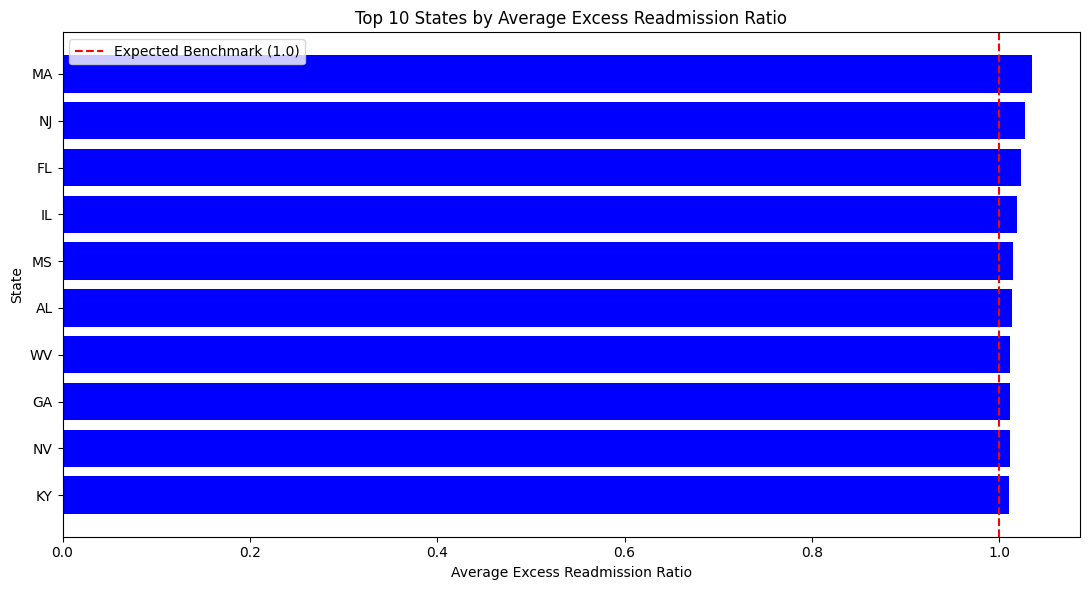

In [14]:

# Select top 10 states
top_10_states = state_analysis.head(10)

# Create bar chart
plt.figure(figsize=(11, 6))

plt.barh(
    top_10_states["State"],
    top_10_states["Average_ERR"],
    color="blue"
)

# Add benchmark line
plt.axvline(
    x=1.0,
    color="red",
    linestyle="--",
    label="Expected Benchmark (1.0)"
)

# Add chart labels
plt.xlabel("Average Excess Readmission Ratio")
plt.ylabel("State")
plt.title("Top 10 States by Average Excess Readmission Ratio")

# Show highest state at top
plt.gca().invert_yaxis()

# Add legend
plt.legend()

plt.tight_layout()
plt.show()


Improve the state comparison chart

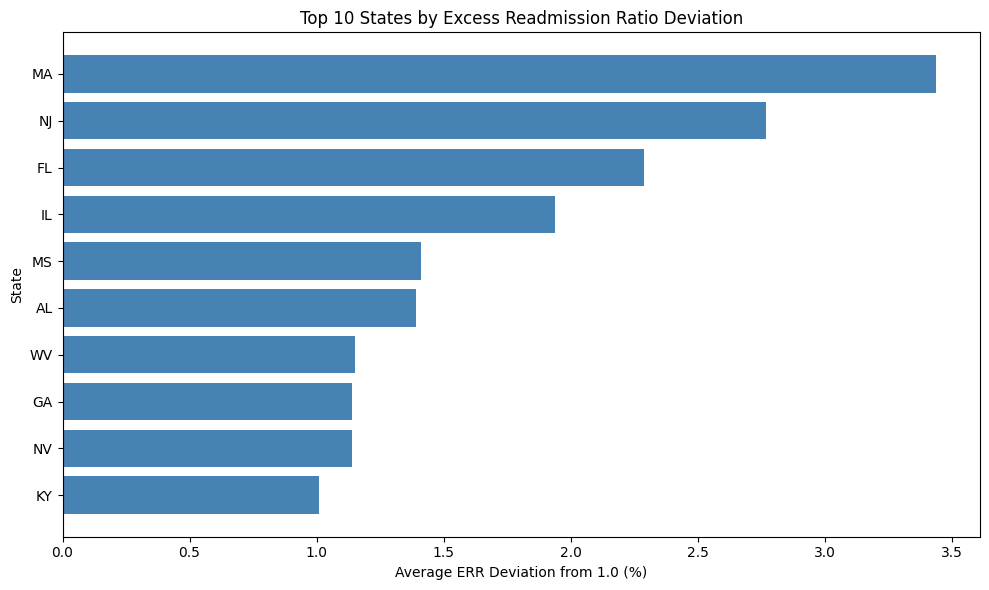

In [15]:

# Select top 10 states
top_10_states = state_analysis.head(10).copy()

# Calculate percentage difference from benchmark
top_10_states["Deviation_Percent"] = (
    (top_10_states["Average_ERR"] - 1) * 100
)

# Create chart
plt.figure(figsize=(10, 6))

plt.barh(
    top_10_states["State"],
    top_10_states["Deviation_Percent"],
    color="steelblue"
)

# Benchmark line at zero deviation
plt.axvline(x=0, color="red", linestyle="--")

plt.xlabel("Average ERR Deviation from 1.0 (%)")
plt.ylabel("State")
plt.title("Top 10 States by Excess Readmission Ratio Deviation")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


Analyze readmission performance by medical condition

Business question: Which medical conditions have the highest average Excess Readmission Ratios?

In [16]:

# Calculate readmission performance by condition
condition_analysis = df_analysis.groupby("Measure Name").agg(
    Average_ERR=("Excess Readmission Ratio", "mean"),
    Total_Records=("Facility ID", "count")
).reset_index()

# Round the average ERR
condition_analysis["Average_ERR"] = (
    condition_analysis["Average_ERR"].round(4)
)

# Sort by highest average ERR
condition_analysis = condition_analysis.sort_values(
    by="Average_ERR",
    ascending=False
)

# Display results
print("Readmission Performance by Medical Condition:")
display(condition_analysis)


Readmission Performance by Medical Condition:


,Measure Name,Average_ERR,Total_Records
4,READM-30-HIP-KNEE-HRRP,1.0040,1447
0,READM-30-AMI-HRRP,1.0018,1736
1,READM-30-CABG-HRRP,1.0018,878
5,READM-30-PN-HRRP,1.0015,2715
3,READM-30-HF-HRRP,1.0014,2621
2,READM-30-COPD-HRRP,1.0011,2323


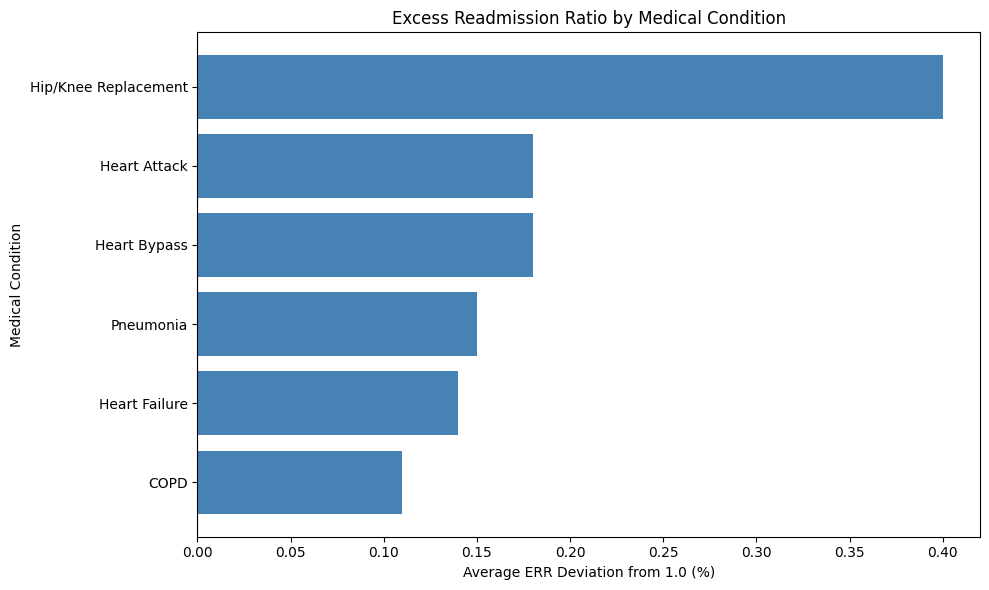

In [17]:

# Create a copy for visualization
condition_chart = condition_analysis.copy()

# Create shorter condition names
condition_names = {
    "READM-30-AMI-HRRP": "Heart Attack",
    "READM-30-CABG-HRRP": "Heart Bypass",
    "READM-30-COPD-HRRP": "COPD",
    "READM-30-HF-HRRP": "Heart Failure",
    "READM-30-HIP-KNEE-HRRP": "Hip/Knee Replacement",
    "READM-30-PN-HRRP": "Pneumonia"
}

condition_chart["Condition"] = (
    condition_chart["Measure Name"].map(condition_names)
)

# Calculate deviation from benchmark
condition_chart["Deviation_Percent"] = (
    (condition_chart["Average_ERR"] - 1) * 100
)

# Create horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    condition_chart["Condition"],
    condition_chart["Deviation_Percent"],
    color="steelblue"
)

plt.axvline(x=0, color="red", linestyle="--")

plt.xlabel("Average ERR Deviation from 1.0 (%)")
plt.ylabel("Medical Condition")
plt.title("Excess Readmission Ratio by Medical Condition")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [18]:

# Identify hospital-measure records above expected
df_analysis["Above_Expected"] = (
    df_analysis["Excess Readmission Ratio"] > 1
)

# Calculate percentage above expected by condition
condition_performance = df_analysis.groupby(
    "Measure Name"
).agg(
    Total_Records=("Facility ID", "count"),
    Above_Expected_Count=("Above_Expected", "sum")
).reset_index()

# Calculate percentage
condition_performance["Above_Expected_Percent"] = (
    condition_performance["Above_Expected_Count"]
    / condition_performance["Total_Records"] * 100
).round(2)

# Add readable condition names
condition_performance["Condition"] = (
    condition_performance["Measure Name"].map(condition_names)
)

# Sort by highest percentage
condition_performance = condition_performance.sort_values(
    "Above_Expected_Percent",
    ascending=False
)

# Display results
display(condition_performance[
    ["Condition", "Total_Records",
     "Above_Expected_Count", "Above_Expected_Percent"]
])


,Condition,Total_Records,Above_Expected_Count,Above_Expected_Percent
1,Heart Bypass,878,438,49.89
0,Heart Attack,1736,862,49.65
3,Heart Failure,2621,1282,48.91
4,Hip/Knee Replacement,1447,693,47.89
2,COPD,2323,1097,47.22
5,Pneumonia,2715,1271,46.81


Create an above-expected performance chart

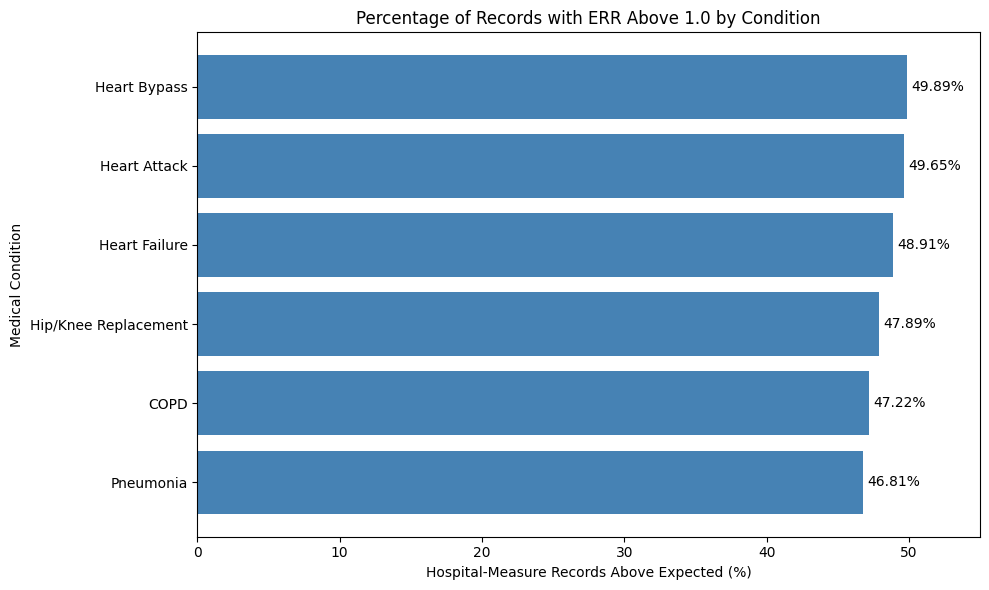

In [19]:

# Create horizontal bar chart
plt.figure(figsize=(10, 6))

bars = plt.barh(
    condition_performance["Condition"],
    condition_performance["Above_Expected_Percent"],
    color="steelblue"
)

# Add percentage labels
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center"
    )

# Format chart
plt.xlabel("Hospital-Measure Records Above Expected (%)")
plt.ylabel("Medical Condition")
plt.title("Percentage of Records with ERR Above 1.0 by Condition")

plt.xlim(0, 55)
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


In [20]:

# Calculate hospital-level performance
hospital_analysis = df_analysis.groupby(
    ["Facility ID", "Facility Name", "State"]
).agg(
    Average_ERR=("Excess Readmission Ratio", "mean"),
    Measures_Available=("Measure Name", "nunique"),
    Above_Expected_Count=("Above_Expected", "sum")
).reset_index()

# Keep hospitals with at least 3 valid measures
hospital_analysis = hospital_analysis[
    hospital_analysis["Measures_Available"] >= 3
].copy()

# Calculate percentage of measures above expected
hospital_analysis["Above_Expected_Percent"] = (
    hospital_analysis["Above_Expected_Count"]
    / hospital_analysis["Measures_Available"] * 100
).round(2)

# Round average ERR
hospital_analysis["Average_ERR"] = (
    hospital_analysis["Average_ERR"].round(4)
)

# Sort by highest average ERR
hospital_analysis = hospital_analysis.sort_values(
    "Average_ERR",
    ascending=False
)

print("Hospitals with at least 3 valid measures:",
      len(hospital_analysis))

print("\nTop 10 Hospitals by Average ERR:")
display(hospital_analysis.head(10))


Hospitals with at least 3 valid measures: 2392

Top 10 Hospitals by Average ERR:


,Facility ID,Facility Name,State,Average_ERR,Measures_Available,Above_Expected_Count,Above_Expected_Percent
185,050030,OROVILLE HOSPITAL,CA,1.2484,5,5,100.00
1260,220105,WINCHESTER HOSPITAL,MA,1.2212,5,5,100.00
633,100260,ST LUCIE MEDICAL CENTER,FL,1.2014,5,5,100.00
1666,330019,"NEW YORK COMMUNITY HOSPITAL OF BROOKLYN, INC.",NY,1.1778,3,3,100.00
1985,370014,ALLIANCEHEALTH DURANT,OK,1.1735,5,5,100.00
1247,220073,BROWN UNIVERSITY HEALTH MORTON HOSPITAL,MA,1.1715,5,4,80.00
1989,370019,GREAT PLAINS REGIONAL MEDICAL CENTER,OK,1.1650,3,1,33.33
1780,330395,ST JOHN'S EPISCOPAL HOSPITAL AT SOUTH SHORE,NY,1.1635,3,3,100.00
1222,220008,STURDY MEMORIAL HOSPITAL,MA,1.1569,4,4,100.00
1250,220080,HOLY FAMILY HOSPITAL,MA,1.1552,5,5,100.00


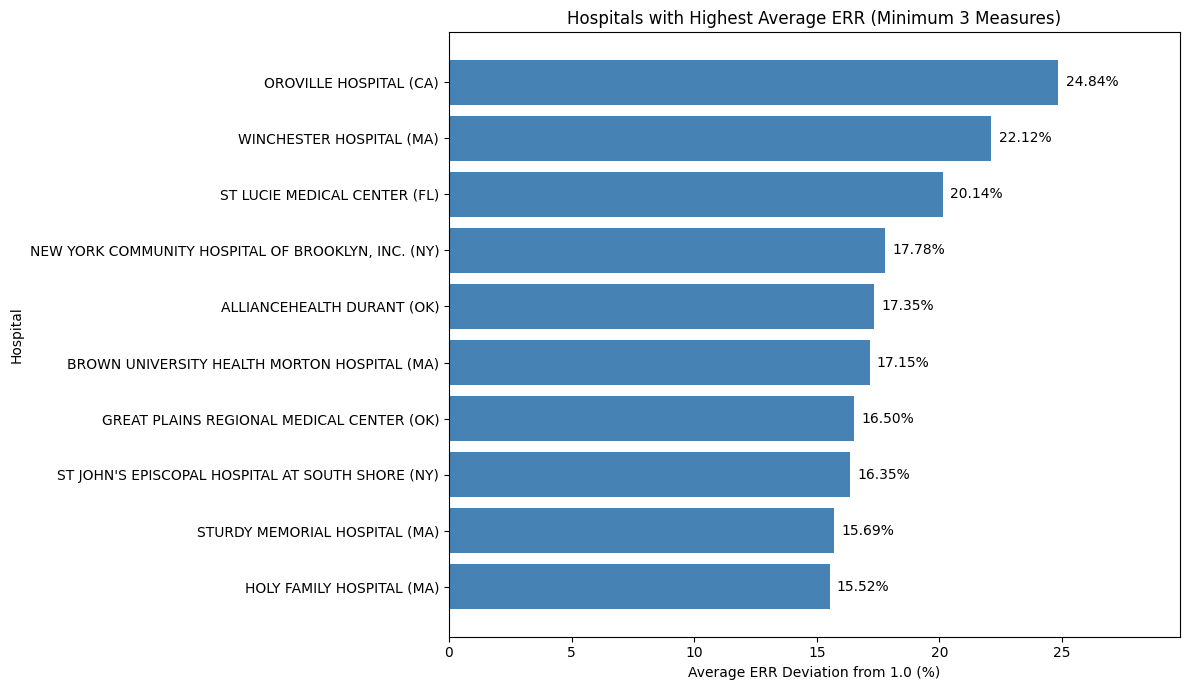

In [21]:

# Select top 10 hospitals
top_hospitals = hospital_analysis.head(10).copy()

# Add state to hospital name
top_hospitals["Hospital_Label"] = (
    top_hospitals["Facility Name"]
    + " (" + top_hospitals["State"] + ")"
)

# Calculate deviation from expected benchmark
top_hospitals["Deviation_Percent"] = (
    (top_hospitals["Average_ERR"] - 1) * 100
)

# Create chart
plt.figure(figsize=(12, 7))

bars = plt.barh(
    top_hospitals["Hospital_Label"],
    top_hospitals["Deviation_Percent"],
    color="steelblue"
)

# Add percentage labels
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center"
    )

plt.xlabel("Average ERR Deviation from 1.0 (%)")
plt.ylabel("Hospital")
plt.title("Hospitals with Highest Average ERR (Minimum 3 Measures)")

plt.gca().invert_yaxis()
plt.xlim(0, top_hospitals["Deviation_Percent"].max() * 1.2)
plt.tight_layout()
plt.show()


Analyze discharge volume and readmission performance

Records with valid discharge data: 8037
Correlation: -0.1296


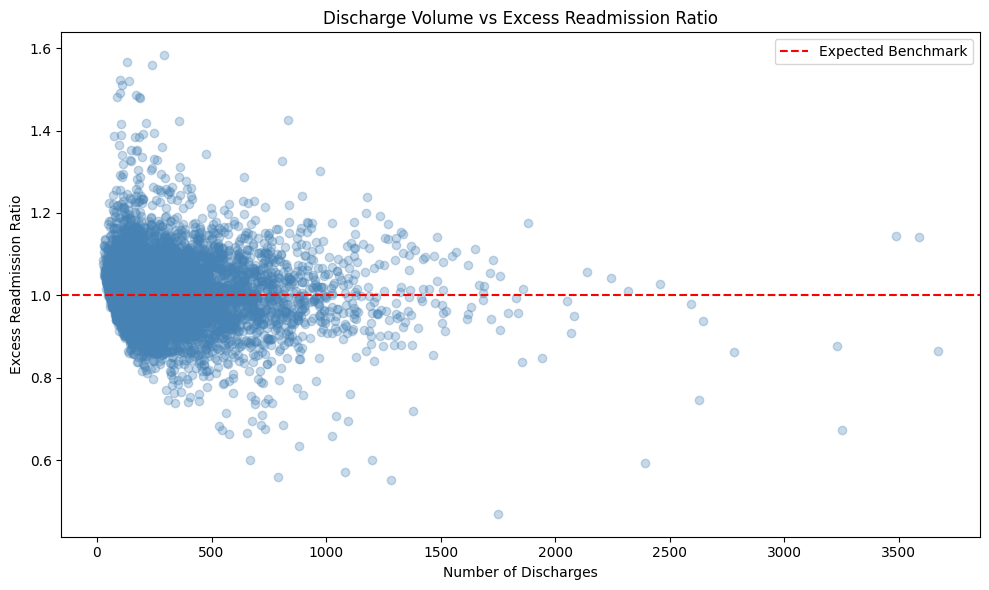

In [23]:

# Keep records with valid discharge counts and ERR
volume_analysis = df_analysis.dropna(
    subset=[
        "Number of Discharges",
        "Excess Readmission Ratio"
    ]
).copy()

# Check number of available records
print("Records with valid discharge data:",
      len(volume_analysis))

# Calculate correlation
correlation = volume_analysis[
    "Number of Discharges"
].corr(
    volume_analysis["Excess Readmission Ratio"]
)

print("Correlation:", round(correlation, 4))

# Create scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    volume_analysis["Number of Discharges"],
    volume_analysis["Excess Readmission Ratio"],
    alpha=0.3,
    color="steelblue"
)

# Add expected benchmark
plt.axhline(
    y=1.0,
    color="red",
    linestyle="--",
    label="Expected Benchmark"
)

plt.xlabel("Number of Discharges")
plt.ylabel("Excess Readmission Ratio")
plt.title("Discharge Volume vs Excess Readmission Ratio")

plt.legend()
plt.tight_layout()
plt.show()


Compare discharge-volume groups

In [24]:

# Create discharge-volume groups using quartiles
volume_analysis["Volume_Group"] = pd.qcut(
    volume_analysis["Number of Discharges"],
    q=4,
    labels=[
        "Low",
        "Medium-Low",
        "Medium-High",
        "High"
    ],
    duplicates="drop"
)

# Calculate average ERR for each group
volume_summary = volume_analysis.groupby(
    "Volume_Group",
    observed=True
).agg(
    Average_ERR=("Excess Readmission Ratio", "mean"),
    Total_Records=("Facility ID", "count"),
    Average_Discharges=("Number of Discharges", "mean")
).reset_index()

# Round values
volume_summary["Average_ERR"] = (
    volume_summary["Average_ERR"].round(4)
)

volume_summary["Average_Discharges"] = (
    volume_summary["Average_Discharges"].round(1)
)

print("Readmission Performance by Discharge Volume:")
display(volume_summary)

# Show correlation from the previous step
print("\nCorrelation:", round(correlation, 4))


Readmission Performance by Discharge Volume:


,Volume_Group,Average_ERR,Total_Records,Average_Discharges
0,Low,1.0273,2022,88.1
1,Medium-Low,1.0110,2008,159.8
2,Medium-High,1.0042,1998,273.5
3,High,0.9937,2009,642.4



Correlation: -0.1296


Analyze discharge volume separately by medical condition

In [25]:

# Calculate discharge volume correlation by condition
condition_volume = volume_analysis.groupby(
    "Measure Name"
).apply(
    lambda group: group["Number of Discharges"].corr(
        group["Excess Readmission Ratio"]
    ),
    include_groups=False
).reset_index(name="Correlation")

# Add readable medical condition names
condition_volume["Condition"] = (
    condition_volume["Measure Name"].map(condition_names)
)

# Round correlation values
condition_volume["Correlation"] = (
    condition_volume["Correlation"].round(4)
)

# Sort by correlation
condition_volume = condition_volume.sort_values(
    "Correlation"
)

# Display results
print("Discharge Volume vs ERR Correlation by Condition:")
display(condition_volume[["Condition", "Correlation"]])


Discharge Volume vs ERR Correlation by Condition:


,Condition,Correlation
4,Hip/Knee Replacement,-0.5895
1,Heart Bypass,-0.4042
0,Heart Attack,-0.2140
3,Heart Failure,-0.0929
2,COPD,-0.0363
5,Pneumonia,0.0331


Visualize correlation by medical condition

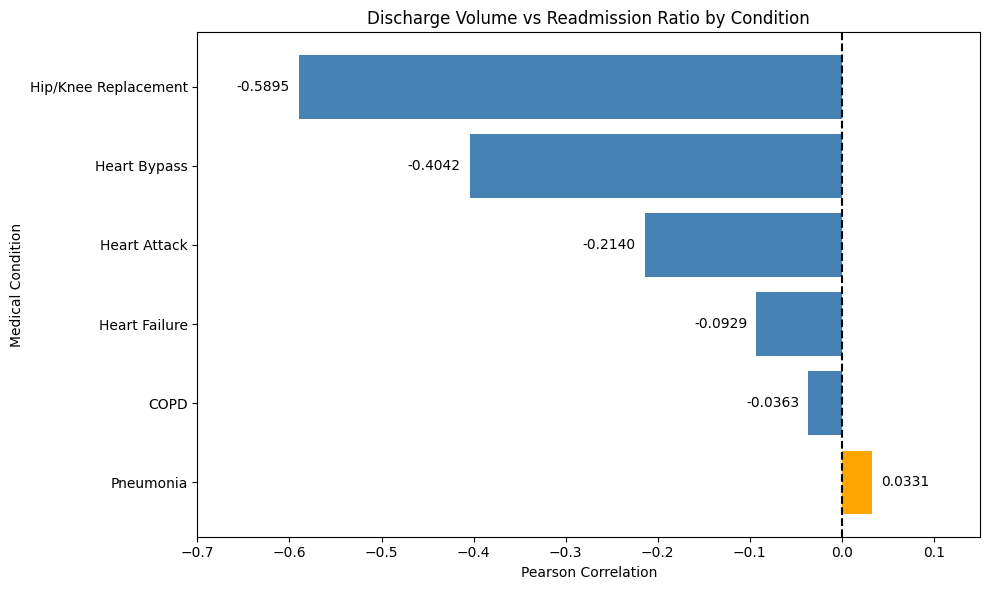

In [26]:

# Create colors based on correlation direction
colors = [
    "steelblue" if value < 0 else "orange"
    for value in condition_volume["Correlation"]
]

# Create horizontal bar chart
plt.figure(figsize=(10, 6))

bars = plt.barh(
    condition_volume["Condition"],
    condition_volume["Correlation"],
    color=colors
)

# Add zero reference line
plt.axvline(x=0, color="black", linestyle="--")

# Add correlation labels
for bar in bars:
    value = bar.get_width()
    plt.text(
        value + (0.01 if value >= 0 else -0.01),
        bar.get_y() + bar.get_height() / 2,
        f"{value:.4f}",
        ha="left" if value >= 0 else "right",
        va="center"
    )

plt.xlabel("Pearson Correlation")
plt.ylabel("Medical Condition")
plt.title("Discharge Volume vs Readmission Ratio by Condition")

plt.xlim(-0.7, 0.15)
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


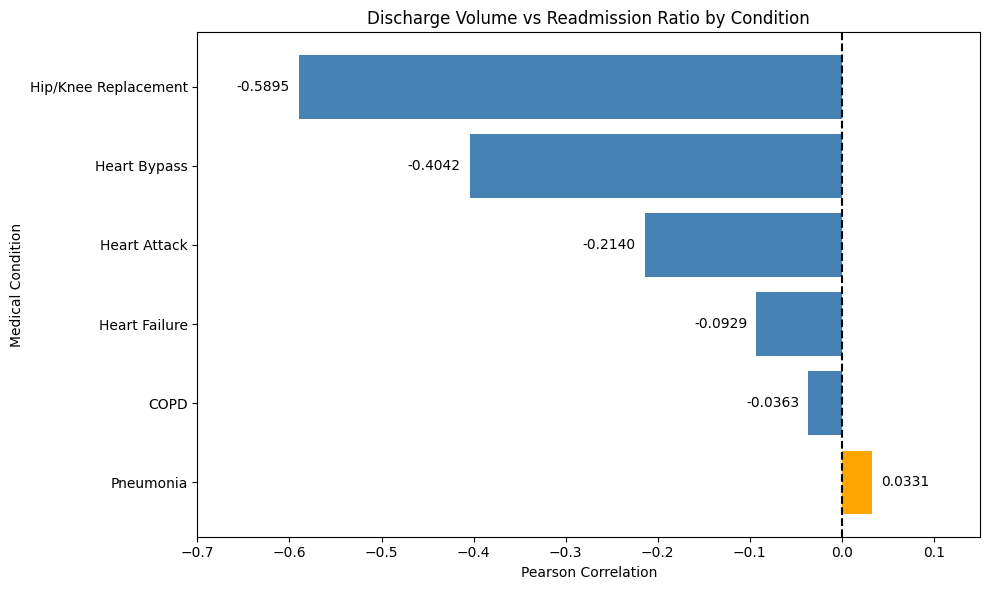

Chart saved successfully!


In [28]:

import os

# Create folder for charts
os.makedirs("charts", exist_ok=True)

# Save the correlation chart
plt.figure(figsize=(10, 6))

colors = [
    "steelblue" if x < 0 else "orange"
    for x in condition_volume["Correlation"]
]

bars = plt.barh(
    condition_volume["Condition"],
    condition_volume["Correlation"],
    color=colors
)

plt.axvline(x=0, color="black", linestyle="--")

for bar in bars:
    value = bar.get_width()
    plt.text(
        value + (0.01 if value >= 0 else -0.01),
        bar.get_y() + bar.get_height() / 2,
        f"{value:.4f}",
        ha="left" if value >= 0 else "right",
        va="center"
    )

plt.xlabel("Pearson Correlation")
plt.ylabel("Medical Condition")
plt.title("Discharge Volume vs Readmission Ratio by Condition")
plt.xlim(-0.7, 0.15)
plt.gca().invert_yaxis()
plt.tight_layout()

# Save image before displaying it
plt.savefig(
    "charts/discharge_volume_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully!")


In [29]:

import os
import matplotlib.pyplot as plt

os.makedirs("charts", exist_ok=True)

# Chart 1: Top 10 states
states = state_analysis.head(10).copy()
states["Deviation"] = (states["Average_ERR"] - 1) * 100

plt.figure(figsize=(10, 6))
plt.barh(states["State"], states["Deviation"], color="steelblue")
plt.gca().invert_yaxis()
plt.xlabel("Average ERR Deviation from 1.0 (%)")
plt.title("Top 10 States by Average ERR Deviation")
plt.tight_layout()
plt.savefig("charts/state_readmission_analysis.png", dpi=300)
plt.close()

# Chart 2: Medical conditions
conditions = condition_analysis.copy()
conditions["Condition"] = conditions["Measure Name"].map(condition_names)
conditions["Deviation"] = (conditions["Average_ERR"] - 1) * 100

plt.figure(figsize=(10, 6))
plt.barh(conditions["Condition"], conditions["Deviation"], color="steelblue")
plt.gca().invert_yaxis()
plt.xlabel("Average ERR Deviation from 1.0 (%)")
plt.title("Readmission Performance by Medical Condition")
plt.tight_layout()
plt.savefig("charts/condition_readmission_analysis.png", dpi=300)
plt.close()

# Chart 3: Above-expected percentages
plt.figure(figsize=(10, 6))
plt.barh(
    condition_performance["Condition"],
    condition_performance["Above_Expected_Percent"],
    color="steelblue"
)
plt.gca().invert_yaxis()
plt.xlabel("Hospital-Measure Records Above Expected (%)")
plt.title("Above-Expected Readmission Performance by Condition")
plt.tight_layout()
plt.savefig("charts/above_expected_readmissions.png", dpi=300)
plt.close()

# Chart 4: Hospital performance
hospitals = hospital_analysis.head(10).copy()
hospitals["Label"] = (
    hospitals["Facility Name"] + " (" + hospitals["State"] + ")"
)
hospitals["Deviation"] = (hospitals["Average_ERR"] - 1) * 100

plt.figure(figsize=(12, 7))
plt.barh(hospitals["Label"], hospitals["Deviation"], color="steelblue")
plt.gca().invert_yaxis()
plt.xlabel("Average ERR Deviation from 1.0 (%)")
plt.title("Hospitals with Highest Average ERR (Minimum 3 Measures)")
plt.tight_layout()
plt.savefig(
    "charts/hospital_readmission_analysis.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()

print("All four charts saved successfully!")


All four charts saved successfully!


In [30]:

import shutil
from google.colab import files

# Create ZIP containing all saved charts
shutil.make_archive("hospital_charts", "zip", "charts")

# Download ZIP file
files.download("hospital_charts.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>